# Red Neuronal: Predicción de Tipo de Cultivo

**Universidad Autónoma de Nuevo León**  
**Facultad de Ingeniería Mecánica y Eléctrica**  

---

## Producto Integrador de Aprendizaje (PIA)

### **Integrantes:**
* **Marco Antonio Méndez Sánchez** — 2177912
* **Alfonso Uriel Rodriguez Ruiz** — 2177756
* **Daniel Humberto Flores Martínez** — 2177905
* **Jared Nathan Hernandez Garibaldi** — 2177817
* **Gamaliel Cruz Feliciano** — 2173901



### Descripción del Proyecto
Modelo de Red Neuronal para la clasificación y predicción del tipo de cultivo ideal basado en parámetros edafoclimáticos (nutrientes del suelo, clima, precipitación, etc.).

### Instalación de dependencias
Esta celda revisa la versión de Python e instala automáticamente las librerías que falten (de `requirements.txt`) en el intérprete del notebook. Solo tarda la primera vez; después solo confirma que todo está instalado.

In [1]:
import sys
import subprocess
import importlib.util

# 1. Revisar la versión de Python (TensorFlow no siempre soporta la más reciente)
version = sys.version.split()[0]
if sys.version_info[:2] != (3, 12):
    print(f"⚠ Estás usando Python {version}. Este proyecto está probado con Python 3.12;")
    print("  si la instalación de TensorFlow falla, crea el entorno con Python 3.12 (ver README.md).")
else:
    print(f"Python {version} ✔")

# 2. Instalar las librerías que falten en el intérprete de este notebook
modulos = ['tensorflow', 'pandas', 'numpy', 'sklearn', 'seaborn', 'matplotlib']
faltantes = [m for m in modulos if importlib.util.find_spec(m) is None]

if faltantes:
    print(f"Faltan: {', '.join(faltantes)}. Instalando desde requirements.txt (puede tardar unos minutos)...")
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', 'requirements.txt'])
    print("Dependencias instaladas ✔")
else:
    print("Todas las dependencias ya están instaladas ✔")

Python 3.12.10 ✔
Todas las dependencias ya están instaladas ✔


### Librerias 

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Semilla fija para que los resultados sean reproducibles (NumPy, TensorFlow y random)
SEMILLA = 42
tf.keras.utils.set_random_seed(SEMILLA)

### Dataframe Análisis, Limpieza y Correlación de variables

In [3]:
df = pd.read_csv('Crop_recommendation.csv')
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [4]:
# Pasar los nombres de las columnas a minúsculas
df.columns = df.columns.str.lower()

# Eliminar valores nulos
print("Valores nulos por columna:\n", df.isnull().sum())
df = df.dropna()

# Cuántas muestras hay por cultivo
print("\nCantidad de muestras por tipo de cultivo:")
print(df['label'].value_counts())

Valores nulos por columna:
 n              0
p              0
k              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Cantidad de muestras por tipo de cultivo:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   n            2200 non-null   int64  
 1   p            2200 non-null   int64  
 2   k            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


In [6]:
# Agrupamos por cultivo y calculamos el promedio de lluvia y temperatura
promedios_por_cultivo = df.groupby('label')[['temperature', 'rainfall']].mean()
print("Promedios climáticos por cultivo:")
print(promedios_por_cultivo)

Promedios climáticos por cultivo:
             temperature    rainfall
label                               
apple          22.630942  112.654779
banana         27.376798  104.626980
blackgram      29.973340   67.884151
chickpea       18.872847   80.058977
coconut        27.409892  175.686646
coffee         25.540477  158.066295
cotton         23.988958   80.398043
grapes         23.849575   69.611829
jute           24.958376  174.792798
kidneybeans    20.115085  105.919778
lentil         24.509052   45.680454
maize          22.389204   84.766988
mango          31.208770   94.704515
mothbeans      28.194920   51.198487
mungbean       28.525775   48.403601
muskmelon      28.663066   24.689952
orange         22.765725  110.474969
papaya         33.723859  142.627839
pigeonpeas     27.741762  149.457564
pomegranate    21.837842  107.528442
rice           23.689332  236.181114
watermelon     25.591767   50.786219


In [7]:
# Rango (mínimo y máximo) de temperatura y pH en el que aparece cada cultivo.
# Las variables son continuas, así que un resumen por rango es más útil que una tabla cruzada.
rangos_por_cultivo = df.groupby('label')[['temperature', 'ph']].agg(['min', 'max']).round(2)
print("Rangos de temperatura y pH por cultivo:")
print(rangos_por_cultivo)

Rangos de temperatura y pH por cultivo:
            temperature           ph      
                    min    max   min   max
label                                     
apple             21.04  24.00  5.51  6.50
banana            25.01  29.91  5.51  6.49
blackgram         25.10  34.95  6.50  7.78
chickpea          17.02  21.00  5.99  8.87
coconut           25.01  29.87  5.50  6.47
coffee            23.06  27.92  6.02  7.49
cotton            22.00  25.99  5.80  7.99
grapes             8.83  41.95  5.51  6.50
jute              23.09  26.99  6.00  7.49
kidneybeans       15.33  24.92  5.50  6.00
lentil            18.06  29.94  5.92  7.84
maize             18.04  26.55  5.51  7.00
mango             27.00  35.99  4.51  6.97
mothbeans         24.02  32.00  3.50  9.94
mungbean          27.01  29.91  6.22  7.20
muskmelon         27.02  29.94  6.00  6.78
orange            10.01  34.91  6.01  8.00
papaya            23.01  43.68  6.50  6.99
pigeonpeas        18.32  36.98  4.55  7.45
pomegranate   

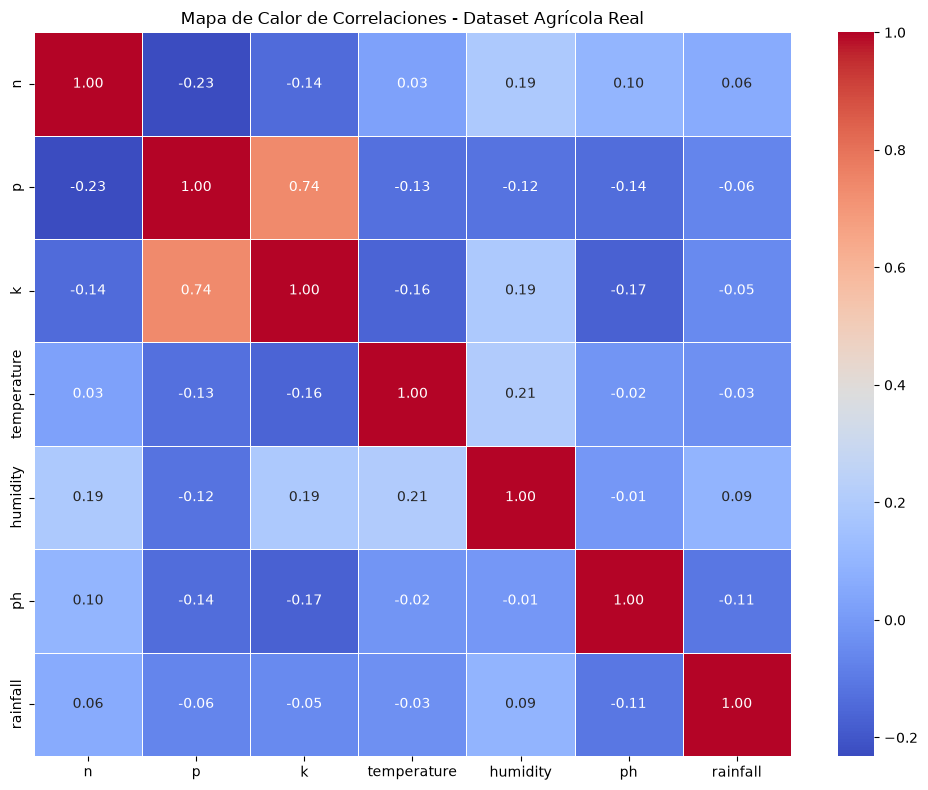

In [8]:
# 1. Seleccionamos solo las columnas numéricas (N, P, K, temp, humedad, etc.)
columnas_num = df.select_dtypes(include=['float64', 'int64'])
# 2. Calculamos la correlación de Pearson
matriz_corr = columnas_num.corr()
# 3. Configuramos el tamaño del gráfico
plt.figure(figsize=(10, 8))
# 4. Dibujamos el Heatmap
# annot=True pone los números dentro de los cuadros
# cmap='coolwarm' usa colores azules (negativa) y rojos (positiva)
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
# Título y mostrar gráfico
plt.title('Mapa de Calor de Correlaciones - Dataset Agrícola Real')
plt.tight_layout()
plt.show()

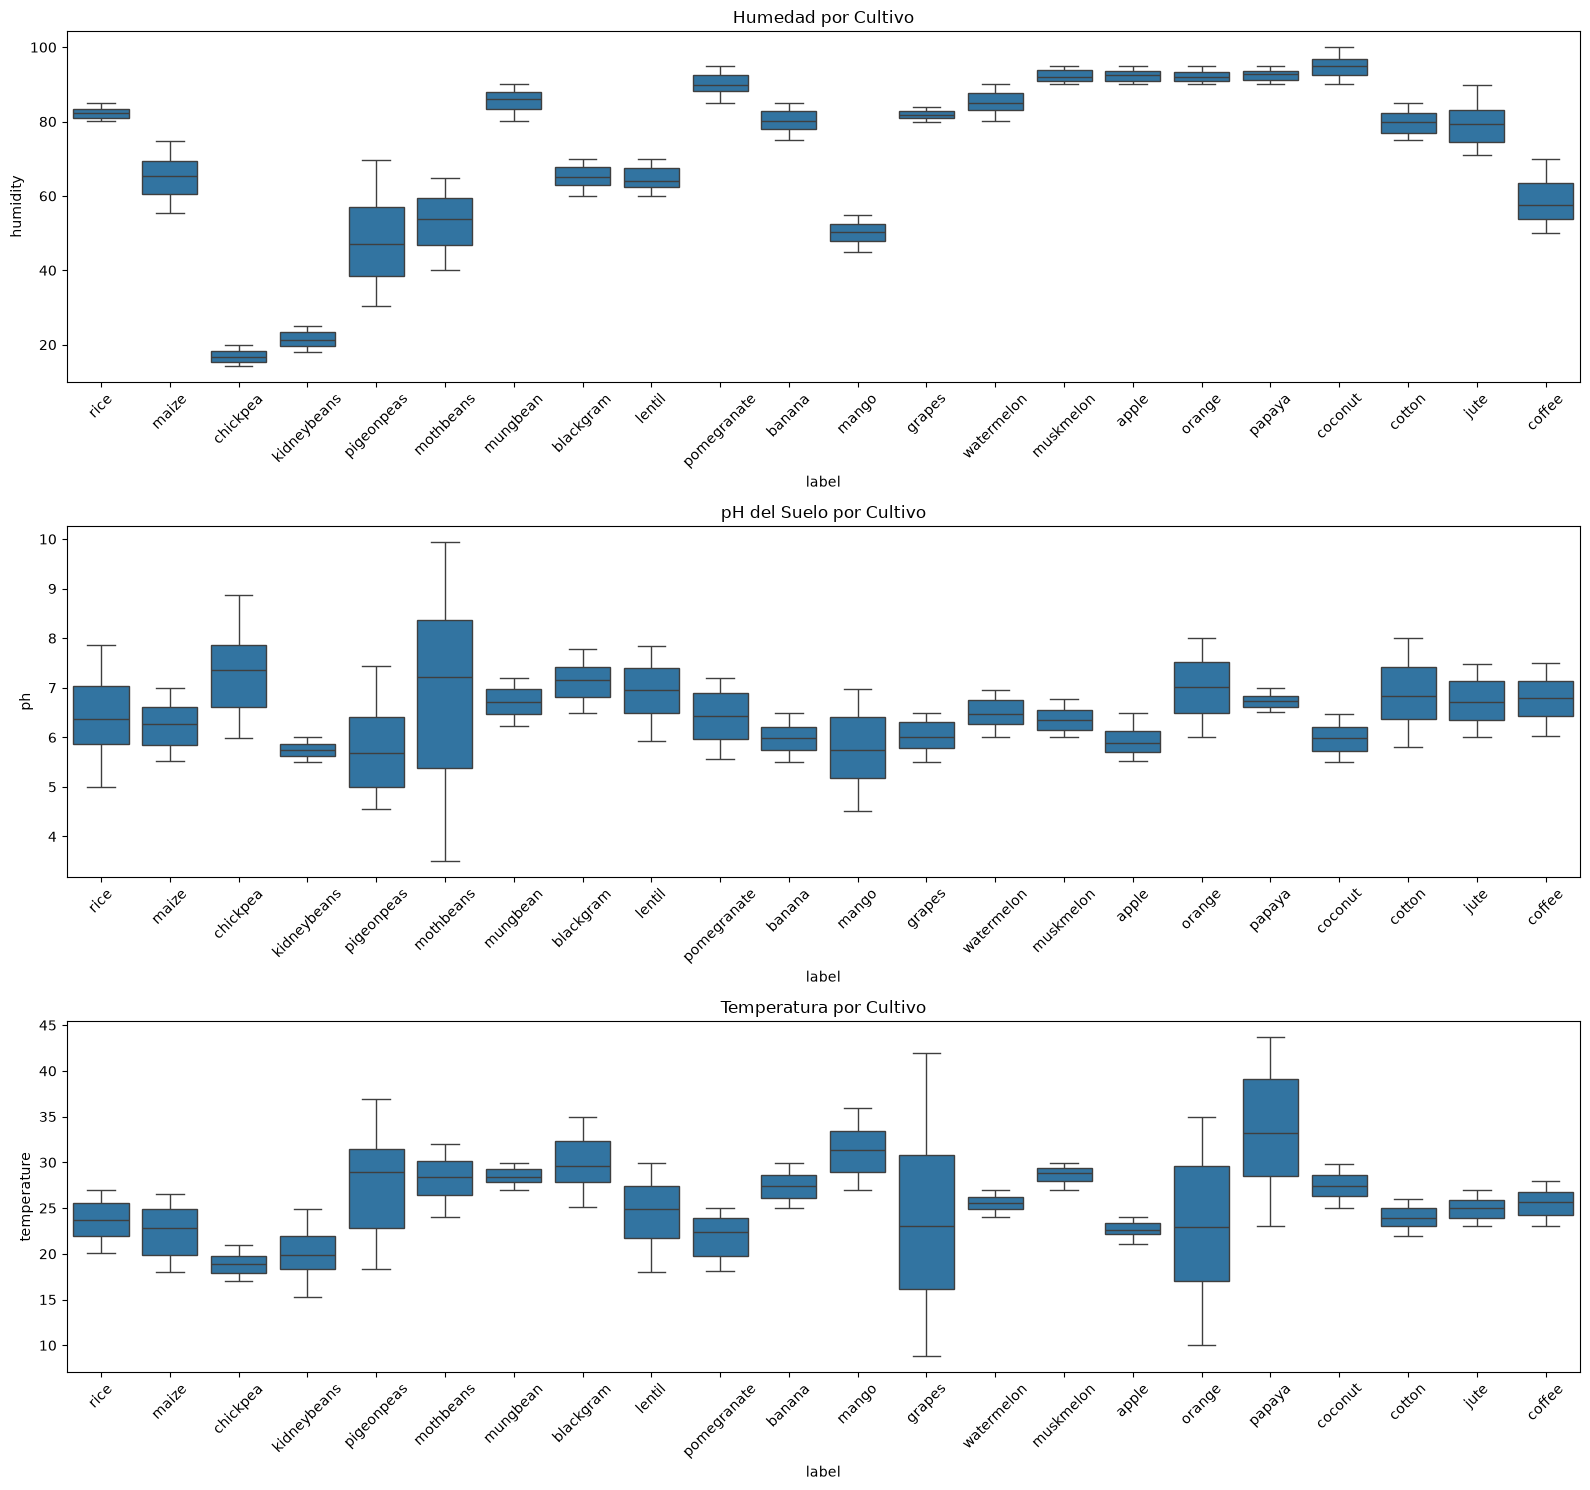

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(16, 15))
# Gráfico 1: Humedad vs Cultivo
sns.boxplot(x='label', y='humidity', data=df, ax=axes[0])
axes[0].set_title('Humedad por Cultivo')
# Gráfico 2: pH del Suelo vs Cultivo
sns.boxplot(x='label', y='ph', data=df, ax=axes[1])
axes[1].set_title('pH del Suelo por Cultivo')
# Gráfico 3: Temperatura vs Cultivo
sns.boxplot(x='label', y='temperature', data=df, ax=axes[2])
axes[2].set_title('Temperatura por Cultivo')
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### Preprocesamiento y Red Neuronal

In [10]:
# Obtener X y Y; Y será la variable objetivo
X = df.drop(columns=['label'])
y = df['label']

# Convertir los nombres de los cultivos a números
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
numero_de_cultivos = len(label_encoder.classes_)
print(f"Total de cultivos a clasificar: {numero_de_cultivos}")

# Dividir en Entrenamiento (70%), Validación (15%) y Prueba (15%).
# 'stratify' mantiene la misma proporción de cada cultivo en los tres conjuntos.
# El conjunto de prueba NO se usa durante el entrenamiento: solo para la evaluación final.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_encoded, test_size=0.30, random_state=SEMILLA, stratify=y_encoded)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEMILLA, stratify=y_temp)
print(f"Entrenamiento: {len(X_train)} | Validación: {len(X_val)} | Prueba: {len(X_test)}")

# Normalizar los datos (el escalador se ajusta solo con entrenamiento)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Crear red neuronal
modelo = Sequential([
    # Capa de entrada (7 variables)
    Input(shape=(X_train_scaled.shape[1],)),

    # Capa oculta 1
    Dense(64, activation='relu'),
    Dropout(0.2),

    # Capa oculta 2
    Dense(32, activation='relu'),

    # Capa de salida (tantas neuronas como cultivos haya)
    Dense(numero_de_cultivos, activation='softmax')
])

# Compilar y Entrenar
modelo.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

# EarlyStopping: detiene el entrenamiento si la pérdida de validación deja de mejorar
# durante 15 épocas y restaura los mejores pesos encontrados.
parada_temprana = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

print("\n--- INICIANDO EL ENTRENAMIENTO ---")
historial = modelo.fit(X_train_scaled, y_train,
                       epochs=200,
                       batch_size=32,
                       validation_data=(X_val_scaled, y_val),
                       callbacks=[parada_temprana],
                       verbose=0)
print(f"--- ENTRENAMIENTO FINALIZADO en {len(historial.history['loss'])} épocas ---")

Total de cultivos a clasificar: 22
Entrenamiento: 1540 | Validación: 330 | Prueba: 330



--- INICIANDO EL ENTRENAMIENTO ---


--- ENTRENAMIENTO FINALIZADO en 136 épocas ---
--- ENTRENAMIENTO FINALIZADO en 136 épocas ---


### Evaluación del Modelo

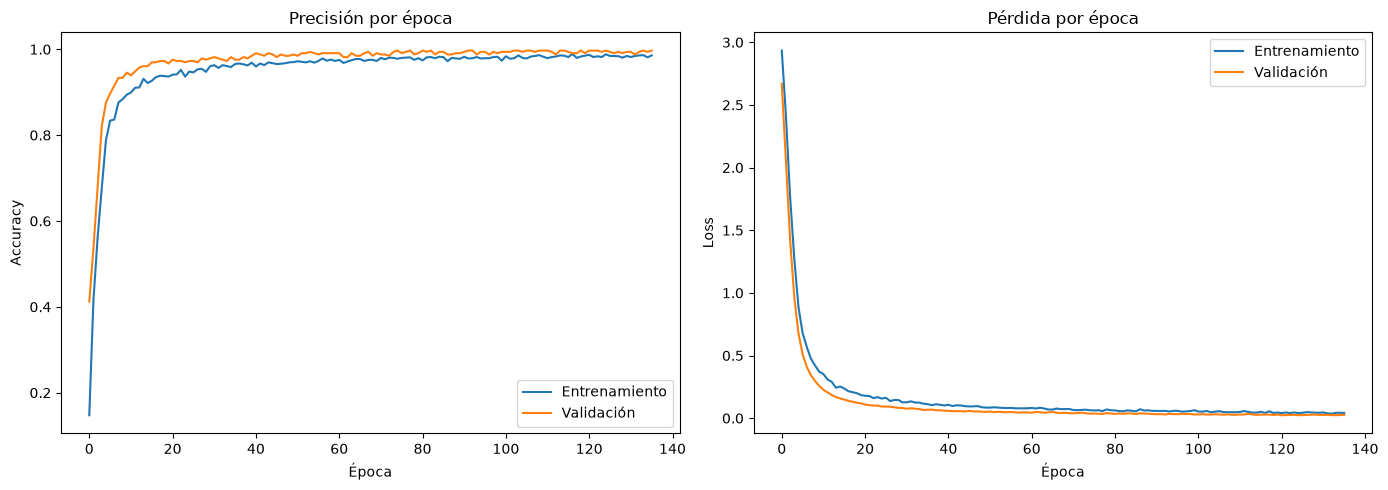

In [11]:
# Curvas de aprendizaje: precisión y pérdida por época
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(historial.history['accuracy'], label='Entrenamiento')
axes[0].plot(historial.history['val_accuracy'], label='Validación')
axes[0].set_title('Precisión por época')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[1].plot(historial.history['loss'], label='Entrenamiento')
axes[1].plot(historial.history['val_loss'], label='Validación')
axes[1].set_title('Pérdida por época')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].legend()
plt.tight_layout()
plt.show()

In [12]:
# Evaluación final con el conjunto de prueba (datos que el modelo nunca vio)
perdida_prueba, precision_prueba = modelo.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Precisión en prueba: {precision_prueba:.2%}")
print(f"Pérdida en prueba:   {perdida_prueba:.4f}\n")

y_pred = np.argmax(modelo.predict(X_test_scaled, verbose=0), axis=1)
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_, digits=3))

Precisión en prueba: 98.48%
Pérdida en prueba:   0.0366



              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        15
      banana      1.000     1.000     1.000        15
   blackgram      1.000     1.000     1.000        15
    chickpea      1.000     1.000     1.000        15
     coconut      1.000     1.000     1.000        15
      coffee      1.000     1.000     1.000        15
      cotton      0.938     1.000     0.968        15
      grapes      1.000     1.000     1.000        15
        jute      0.875     0.933     0.903        15
 kidneybeans      1.000     1.000     1.000        15
      lentil      1.000     1.000     1.000        15
       maize      1.000     0.933     0.966        15
       mango      1.000     1.000     1.000        15
   mothbeans      1.000     1.000     1.000        15
    mungbean      1.000     1.000     1.000        15
   muskmelon      1.000     0.933     0.966        15
      orange      1.000     1.000     1.000        15
      papaya      1.000    

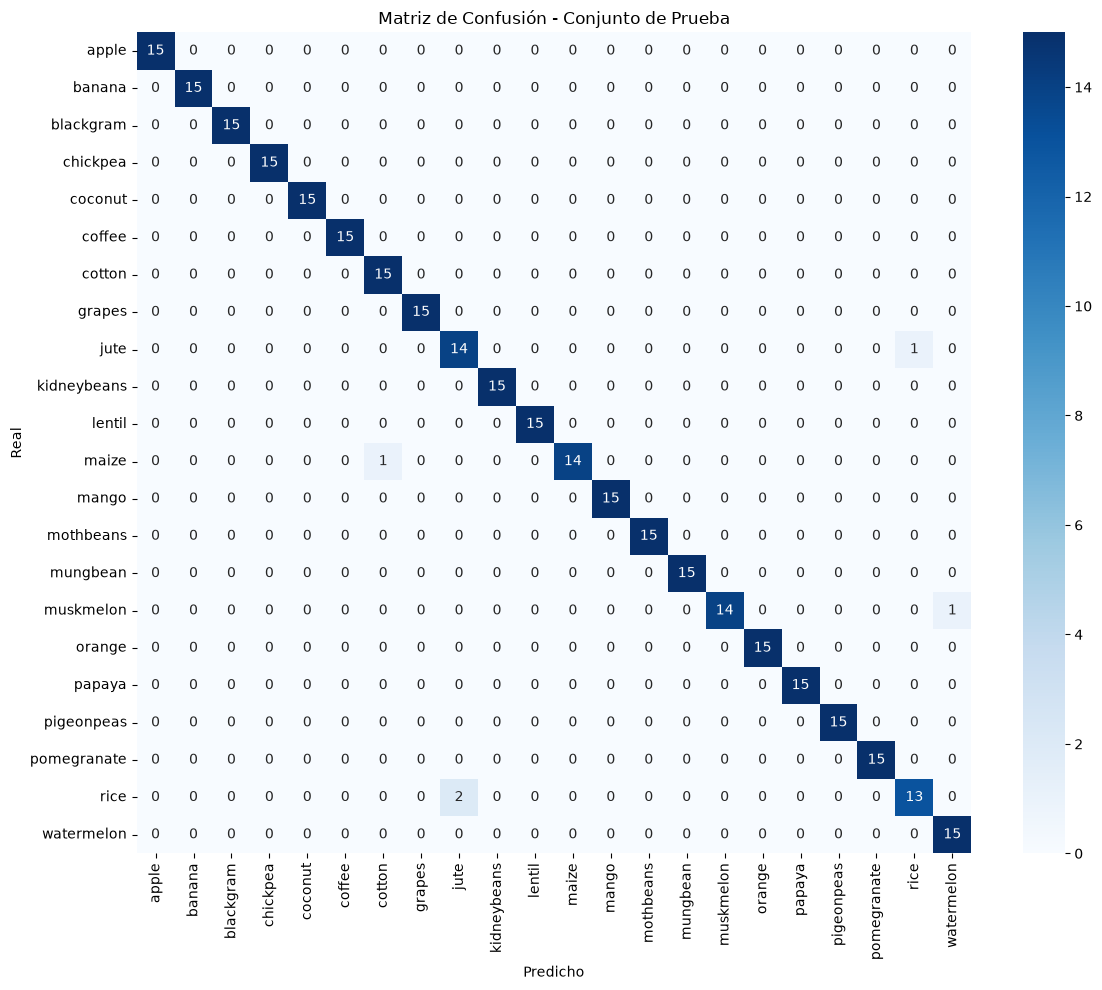

In [13]:
# Matriz de confusión: filas = cultivo real, columnas = cultivo predicho
matriz = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title('Matriz de Confusión - Conjunto de Prueba')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.tight_layout()
plt.show()

### Predicción

In [14]:
# Rango de valores vistos durante el entrenamiento. Fuera de él la red "extrapola"
# y su predicción no es confiable, aunque muestre una probabilidad alta.
rangos_entrenamiento = X_train.agg(['min', 'max'])

def revisar_rangos(datos):
    avisos = []
    for columna in datos.columns:
        valor = datos[columna].iloc[0]
        minimo, maximo = rangos_entrenamiento[columna]
        if not (minimo <= valor <= maximo):
            avisos.append(f"{columna} = {valor} fuera del rango del dataset [{minimo:.1f}, {maximo:.1f}]")
    return avisos

def recomendar_cultivo(N, P, K, temperatura, humedad, ph, lluvia, top=3):
    # 1. Poner los datos en el formato que espera el escalador (una fila, 7 columnas)
    datos_nuevos = pd.DataFrame([[N, P, K, temperatura, humedad, ph, lluvia]], columns=X.columns)

    # Avisar si algún valor está fuera de lo que el modelo conoce
    for aviso in revisar_rangos(datos_nuevos):
        print(f"⚠ AVISO: {aviso}. La predicción puede no ser confiable.")

    # 2. Normalizar los datos igual que en el entrenamiento
    datos_escalados = scaler.transform(datos_nuevos)

    # 3. Pedirle a la Red Neuronal la predicción (devuelve una probabilidad por cultivo)
    probabilidades = modelo.predict(datos_escalados, verbose=0)[0]

    # 4. Ordenar los cultivos de mayor a menor probabilidad y quedarnos con los 'top' mejores
    mejores = np.argsort(probabilidades)[::-1][:top]

    # 5. Traducir los números a nombres de cultivo
    return [(label_encoder.inverse_transform([i])[0], float(probabilidades[i])) for i in mejores]

# Ejemplo: N=30, P=45, K=80, Temp=28.5°C, Humedad=60%, pH=7.8, Lluvia=550mm
# (la lluvia de 550mm está fuera del rango del dataset, por eso aparece un aviso)
resultado = recomendar_cultivo(30, 45, 80, 28.5, 60.0, 7.8, 550.0)
print("\n=============================================")
print(f"EL CULTIVO ÓPTIMO RECOMENDADO ES: {resultado[0][0].upper()}")
print("=============================================")
print("Top 3:")
for cultivo, prob in resultado:
    print(f"  {cultivo:<12} {prob:.1%}")

⚠ AVISO: rainfall = 550.0 fuera del rango del dataset [20.2, 298.6]. La predicción puede no ser confiable.



EL CULTIVO ÓPTIMO RECOMENDADO ES: RICE
Top 3:
  rice         100.0%
  jute         0.0%
  pigeonpeas   0.0%


### Guardar el modelo para la interfaz

In [15]:
import pickle
from pathlib import Path

carpeta = Path('modelo_entrenado')
carpeta.mkdir(exist_ok=True)

modelo.save(carpeta / 'modelo.keras')

preprocesadores = {
    'scaler': scaler,
    'label_encoder': label_encoder,
    'columnas': list(X.columns),
    'rangos': rangos_entrenamiento.to_dict(),
    'precision_prueba': float(precision_prueba),
}
with open(carpeta / 'preprocesadores.pkl', 'wb') as f:
    pickle.dump(preprocesadores, f)

print('Guardado en', carpeta.resolve())
for archivo in sorted(carpeta.iterdir()):
    print(f'  {archivo.name}  ({archivo.stat().st_size / 1024:.1f} KB)')

Guardado en C:\Users\jared\Documents\red-neuronal-agricultura\modelo_entrenado
  modelo.keras  (66.0 KB)
  preprocesadores.pkl  (1.3 KB)
